# Time Series - Resampling

In [ ]:
! pip install pandas-datareader==0.10.0
!pip install yfinance
! pip install --upgrade yfinance

import yfinance as yf
import pandas as pd
import pandas_datareader.data as web
import datetime as dt
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import date

#Clear output
from google.colab import output
output.clear()

### Load the data

In [ ]:
# download the data
start = dt.datetime(2024,1,2)
end = dt.datetime(2024,12,10)

apple = yf.download('AAPL', start, end) # Apple
shell = yf.download('SHEL', start, end) # Shell
ng = yf.download('NOC', start, end) # Northrop Grumman
tsm = yf.download('TSM', start, end) # Taiwan Semiconductor Manufacturing Company (TSMC)
rio = yf.download('RIO', start, end) # Rio Tinto Group
ge = yf.download('GE', start, end) # General Electric Company
gs = yf.download('GS', start, end) # The Goldman Sachs Group
bond = yf.download('BOND', start, end) # PIMCO Active Bond Exchange-Traded Fund
btc = yf.download('BTC-USD', start, end) # Bitcoin USD
xrp = yf.download('XRP-USD', start, end) # XRP USD

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [ ]:
# display the data
apple

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,,
2024-01-02,184.734985,185.639999,188.440002,183.889999,187.149994,82488700
2024-01-03,183.351761,184.250000,185.880005,183.429993,184.220001,58414500
2024-01-04,181.023163,181.910004,183.089996,180.880005,182.149994,71983600
2024-01-05,180.296707,181.179993,182.759995,180.169998,181.990005,62303300
2024-01-08,184.655365,185.559998,185.600006,181.500000,182.089996,59144500
...,...,...,...,...,...,...
2024-12-03,242.649994,242.649994,242.759995,238.899994,239.809998,38861000
2024-12-04,243.009995,243.009995,244.110001,241.250000,242.869995,44383900


In [ ]:
# create a portfolio
portfolio = pd.concat([apple.add_suffix("_Apple"), shell.add_suffix("_Shell"), ng.add_suffix("_Northrop"),tsm.add_suffix("_TSMC"), rio.add_suffix("_RioTinto"), ge.add_suffix("_GE"), gs.add_suffix("_GoldmanSachs"), bond.add_suffix("_Bond"), btc.add_suffix("_Bitcoin"), xrp.add_suffix("_Ripple")], axis=1)
portfolio_gefilterd = portfolio.loc[:, ["Close_Apple", "Close_Shell", "Close_Northrop", "Close_TSMC","Close_RioTinto","Close_GE","Close_GoldmanSachs","Close_Bond","Close_Bitcoin","Close_Ripple"]]
portfolio_gefilterd.columns = ["Close_Apple", "Close_Shell", "Close_Northrop", "Close_TSMC","Close_RioTinto","Close_GE","Close_GoldmanSachs","Close_Bond","Close_Bitcoin","Close_Ripple"]
portfolio_gefilterd

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple
Date,,,,,,,,,,
2024-01-02,185.639999,65.910004,470.089996,101.529999,74.260002,100.518753,388.299988,91.940002,44957.968750,0.625363
2024-01-03,184.250000,66.930000,474.880005,100.169998,73.550003,99.010376,381.790009,92.209999,42848.175781,0.582580
2024-01-04,181.910004,66.360001,471.730011,99.129997,73.040001,99.489227,382.950012,91.690002,44179.921875,0.588226
2024-01-05,181.179993,65.730003,469.890015,99.610001,72.639999,100.790108,386.440002,91.510002,44162.691406,0.576486
2024-01-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,43989.195312,0.568512
...,...,...,...,...,...,...,...,...,...,...
2024-12-05,243.039993,64.349998,479.570007,204.300003,63.520000,172.910004,596.799988,92.629997,96593.570312,2.295206
2024-12-06,242.839996,63.250000,473.649994,203.020004,62.110001,175.580002,599.679993,92.910004,99920.710938,2.424737
2024-12-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,99923.335938,2.616624


In [ ]:
# forward fill and display the data again
portfolio = portfolio_gefilterd.ffill()
portfolio

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple
Date,,,,,,,,,,
2024-01-02,185.639999,65.910004,470.089996,101.529999,74.260002,100.518753,388.299988,91.940002,44957.968750,0.625363
2024-01-03,184.250000,66.930000,474.880005,100.169998,73.550003,99.010376,381.790009,92.209999,42848.175781,0.582580
2024-01-04,181.910004,66.360001,471.730011,99.129997,73.040001,99.489227,382.950012,91.690002,44179.921875,0.588226
2024-01-05,181.179993,65.730003,469.890015,99.610001,72.639999,100.790108,386.440002,91.510002,44162.691406,0.576486
2024-01-06,181.179993,65.730003,469.890015,99.610001,72.639999,100.790108,386.440002,91.510002,43989.195312,0.568512
...,...,...,...,...,...,...,...,...,...,...
2024-12-05,243.039993,64.349998,479.570007,204.300003,63.520000,172.910004,596.799988,92.629997,96593.570312,2.295206
2024-12-06,242.839996,63.250000,473.649994,203.020004,62.110001,175.580002,599.679993,92.910004,99920.710938,2.424737
2024-12-07,242.839996,63.250000,473.649994,203.020004,62.110001,175.580002,599.679993,92.910004,99923.335938,2.616624


In [ ]:
# summary statistics for this data
portfolio.describe()

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple
count,343.000000,343.000000,343.000000,343.000000,343.000000,343.000000,343.000000,343.000000,343.000000,343.000000
mean,204.429592,68.384810,477.780408,158.060495,66.099504,156.051596,462.874052,91.892857,63954.809129,0.638883
std,23.478242,3.577466,31.736504,26.996278,3.212626,25.566508,63.938445,1.415015,12509.573538,0.351975
min,165.000000,61.040001,423.420013,99.129997,59.709999,99.010376,376.910004,89.040001,39507.367188,0.419823
25%,183.050003,65.475002,454.500000,138.279999,63.355000,140.019951,401.994995,90.970001,58728.376953,0.519116
50%,210.619995,68.459999,471.899994,161.940002,65.980003,162.350006,461.179993,91.650002,63811.863281,0.549004
75%,226.434998,71.879997,506.660004,179.584999,68.400002,173.245003,499.024994,92.760002,68298.156250,0.597871
max,246.750000,74.169998,543.880005,205.839996,74.260002,194.229996,608.570007,95.320000,101236.015625,2.713805


### Visualising the data

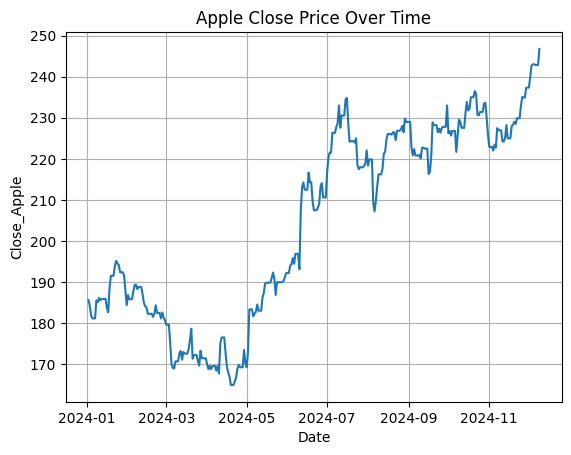

In [ ]:
# Assuming 'portfolio' is your DataFrame with 'Close_Apple' and 'Date' columns
plt.plot(portfolio.index, portfolio['Close_Apple'])
plt.xlabel('Date')
plt.ylabel('Close_Apple')
plt.title('Apple Close Price Over Time')
plt.grid(True)
plt.show()

<Axes: xlabel='Date'>

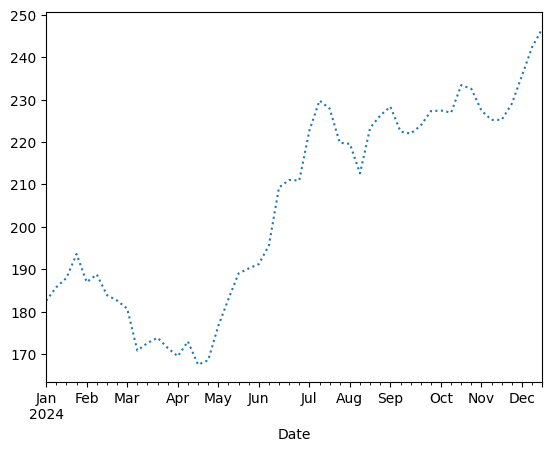

In [ ]:
# resampling the data per week and plot again
weekly = portfolio['Close_Apple'].resample('W').mean()
weekly.plot(style=[':'])

<Axes: xlabel='Date'>

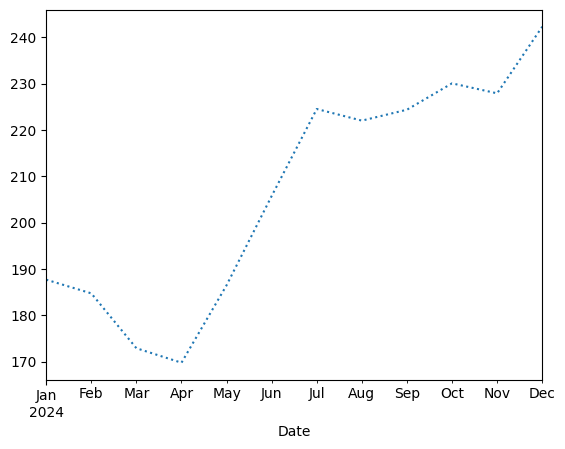

In [ ]:
# resampling the data per month and plot again
monthly = portfolio['Close_Apple'].resample('ME').mean()
monthly.plot(style=[':'])

/usr/local/lib/python3.10/dist-packages/pandas/plotting/_matplotlib/core.py:1561: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(left, right)


<Axes: xlabel='Date'>

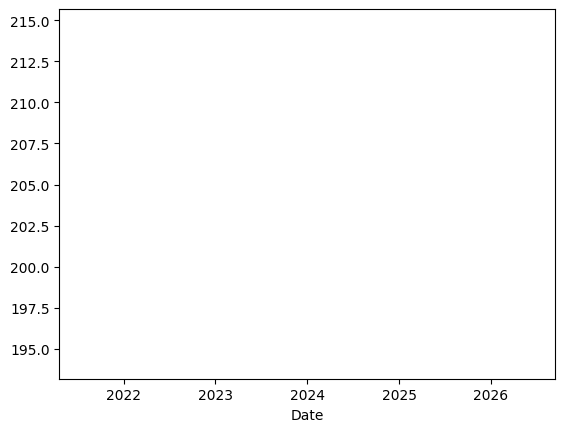

In [ ]:
# resampling the data per year and plot again
yearly = portfolio['Close_Apple'].resample('YE').mean()
yearly.plot(style=[':'])

### Digging into the data

In [ ]:
ticker = yf.Ticker("AAPL")

data = ticker.history(interval="1h", start="2024-1-02", end="2024-12-10")

In [ ]:
data.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Datetime,,,,,,,
2024-01-02 09:30:00-05:00,187.800995,188.440002,186.009995,186.189896,21173291,0.0,0.0
2024-01-02 10:30:00-05:00,186.179993,186.904999,185.184296,186.804993,9010595,0.0,0.0
2024-01-02 11:30:00-05:00,186.800003,187.350006,186.570007,186.615005,6143754,0.0,0.0
2024-01-02 12:30:00-05:00,186.615005,187.039993,185.259995,185.294998,5381701,0.0,0.0
2024-01-02 13:30:00-05:00,185.289993,185.539993,184.229996,184.494995,7228643,0.0,0.0


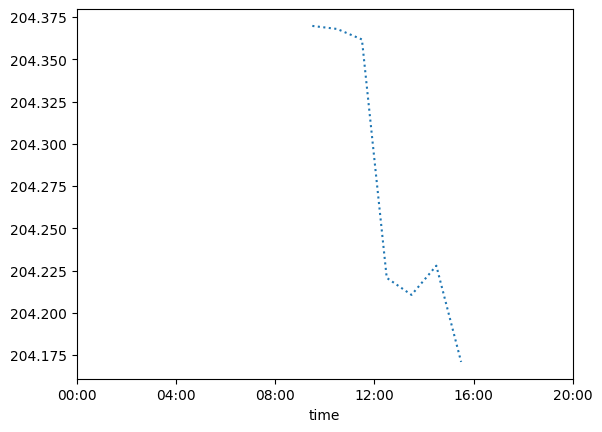

In [ ]:
# look at average daily price by hour
# transform data by using of groupby
by_time = data['Close'].groupby(data.index.time).mean()
hourly_ticks = 4 * 60 * 60 * np.arange(6)
by_time.plot(xticks=hourly_ticks, style=[':']);

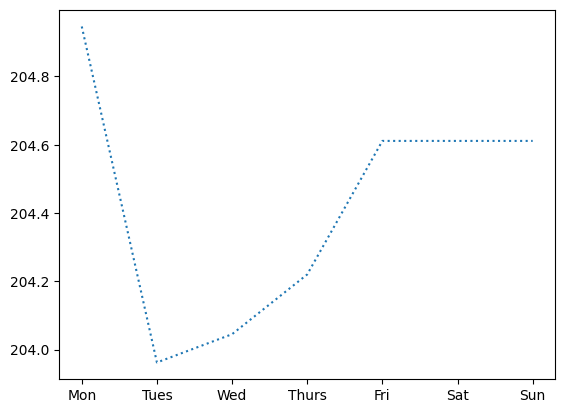

In [ ]:
# alternatively: look at daily price by day of the week
by_weekday = portfolio['Close_Apple'].groupby(portfolio.index.dayofweek).mean()
by_weekday.index = ['Mon', 'Tues', 'Wed', 'Thurs', 'Fri', 'Sat', 'Sun']
by_weekday.plot(style=[':']);

In [ ]:
ticker = yf.Ticker("BTC-USD")

data2 = ticker.history(interval="1h", start="2024-1-02", end="2024-12-10")

In [ ]:
data2.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Datetime,,,,,,,
2024-01-02 00:00:00+00:00,44187.140625,45069.960938,44176.949219,45069.960938,0,0.0,0.0
2024-01-02 01:00:00+00:00,45121.183594,45381.257812,44754.218750,44883.664062,2205095936,0.0,0.0
2024-01-02 02:00:00+00:00,44882.656250,45398.496094,44882.656250,45398.496094,1181814784,0.0,0.0
2024-01-02 03:00:00+00:00,45412.664062,45474.234375,45224.281250,45421.730469,1125044224,0.0,0.0
2024-01-02 04:00:00+00:00,45426.203125,45460.750000,45215.113281,45216.746094,678227968,0.0,0.0


In [ ]:
# now compare hourly trend of weekdays with hourly trend of weekends
weekend = np.where(data2.index.weekday < 5, 'Weekday', 'Weekend')
by_time = data2['Close'].groupby([weekend, data2.index.time]).mean()

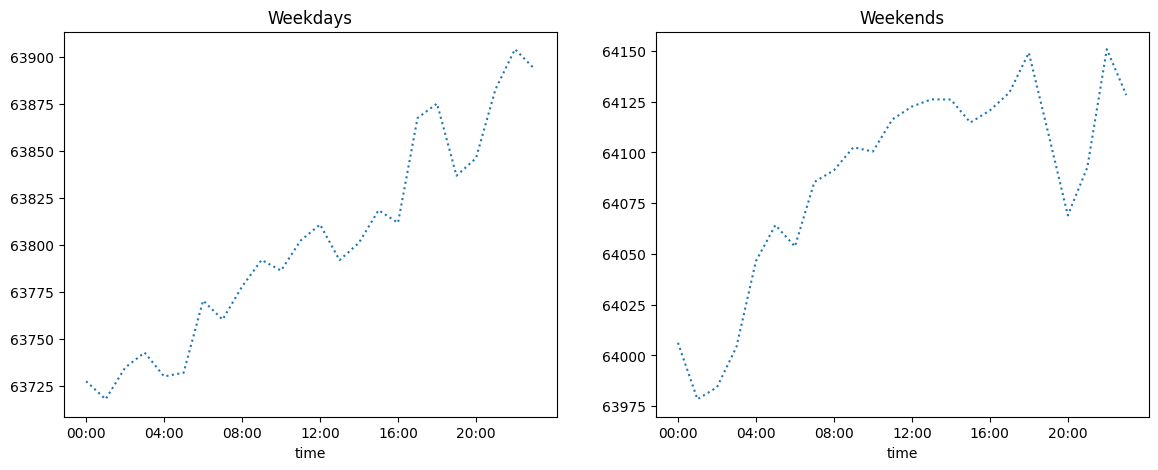

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
by_time.loc['Weekday'].plot(ax=ax[0], title='Weekdays',
                           xticks=hourly_ticks, style=[':'])
by_time.loc['Weekend'].plot(ax=ax[1], title='Weekends',
                           xticks=hourly_ticks, style=[':']);

# Opdracht
Onderzoek voor minimaal 1 van jullie financiele producten, indicatoren en grondstoffen of er een patroon in de tijd te vinden is.